# Used Car Price Prediction

## Introduction

The goal of this project is to build a regression machine learning model that estimates the market price of a used car in US dollars.

The project follows the complete machine learning workflow:

- exploratory data analysis;
- data cleaning;
- feature engineering;
- preprocessing;
- model comparison;
- model evaluation;
- final model selection.

The target variable is `priceUSD`.

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ---------------------------------------------------------
# PROJECT PATHS
# ---------------------------------------------------------

current_dir = os.getcwd()

# VS Code can start the notebook either from the project root
# or from the notebooks directory.
if os.path.basename(current_dir).lower() == "notebooks":
    project_root = os.path.abspath(
        os.path.join(current_dir, "..")
    )
else:
    project_root = current_dir

src_dir = os.path.join(
    project_root,
    "src"
)

if project_root not in sys.path:
    sys.path.insert(
        0,
        project_root
    )

if src_dir not in sys.path:
    sys.path.insert(
        0,
        src_dir
    )


# ---------------------------------------------------------
# PROJECT MODULES
# ---------------------------------------------------------

from src.data_cleaning import clean_data
from src.feature_engineering import add_features
from src.data_preprocessing import (
    FEATURES,
    build_preprocessor
)


# ---------------------------------------------------------
# LOAD DATA
# ---------------------------------------------------------

data_file = os.path.join(
    project_root,
    "data",
    "cars.csv"
)

df = pd.read_csv(
    data_file
)

print(
    "Project root:",
    project_root
)

print(
    "Dataset shape:",
    df.shape
)

df.head()

Project root: h:\Lekcije IT Akademija\7.Introduction to machine learning\Modul 5\Sasa_Ivanovic_Car_Price_Prediction
Dataset shape: (56244, 12)


,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
0,mazda,2,5500,2008,with mileage,162000.0,petrol,1500.0,burgundy,mechanics,front-wheel drive,B
1,mazda,2,5350,2009,with mileage,120000.0,petrol,1300.0,black,mechanics,front-wheel drive,B
2,mazda,2,7000,2009,with mileage,61000.0,petrol,1500.0,silver,auto,front-wheel drive,B
3,mazda,2,3300,2003,with mileage,265000.0,diesel,1400.0,white,mechanics,front-wheel drive,B
4,mazda,2,5200,2008,with mileage,97183.0,diesel,1400.0,gray,mechanics,front-wheel drive,B


## 1. Exploratory Data Analysis

The dataset is first inspected to understand its structure, data types, missing values and the distribution of the target variable.

In [2]:
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nPrice statistics:")
print(df["priceUSD"].describe())

<class 'pandas.DataFrame'>
RangeIndex: 56244 entries, 0 to 56243
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make                 56244 non-null  str    
 1   model                56244 non-null  str    
 2   priceUSD             56244 non-null  int64  
 3   year                 56244 non-null  int64  
 4   condition            56244 non-null  str    
 5   mileage(kilometers)  56244 non-null  float64
 6   fuel_type            56244 non-null  str    
 7   volume(cm3)          56197 non-null  float64
 8   color                56244 non-null  str    
 9   transmission         56244 non-null  str    
 10  drive_unit           54339 non-null  str    
 11  segment              50953 non-null  str    
dtypes: float64(2), int64(2), str(8)
memory usage: 5.1 MB

Missing values:
make                      0
model                     0
priceUSD                  0
year                      0
condition      

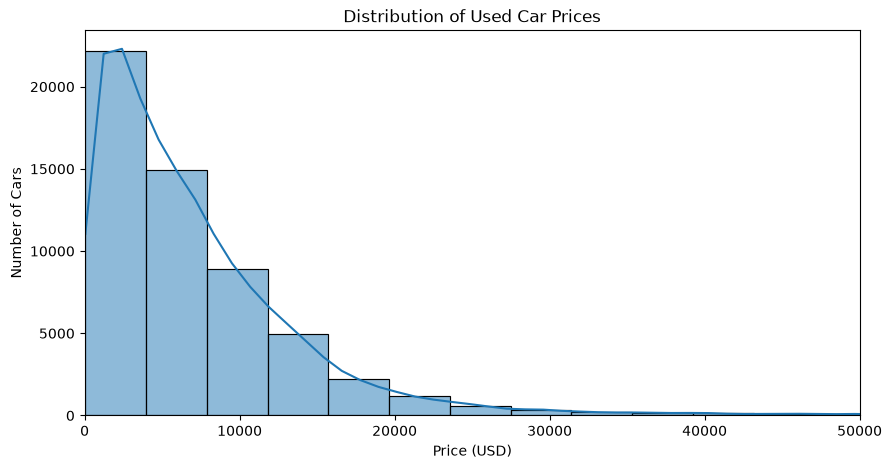

In [3]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["priceUSD"],
    bins=60,
    kde=True
)

plt.title("Distribution of Used Car Prices")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Cars")
plt.xlim(0, 50000)

plt.show()

The price distribution is strongly right-skewed. Most cars are in the lower and middle price ranges, while a relatively small number of very expensive cars create a long right tail.

Because of this skewness, the target variable will be logarithmically transformed during model training.

In [4]:
clean_df = clean_data(df)

print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))

Rows before cleaning: 56244
Rows after cleaning: 55889
Rows removed: 355


In [5]:
model_df = add_features(
    clean_df
)

model_df[
    [
        "make",
        "model",
        "year",
        "car_age",
        "mileage_km",
        "mileage_per_year",
        "engine_volume_liters",
        "is_newer_car",
        "is_high_mileage",
        "brand_model"
    ]
].head()

,make,model,year,car_age,mileage_km,mileage_per_year,engine_volume_liters,is_newer_car,is_high_mileage,brand_model
0,mazda,2,2008,12,162000.0,13500.000000,1.5,0,0,mazda_2
1,mazda,2,2009,11,120000.0,10909.090909,1.3,0,0,mazda_2
2,mazda,2,2009,11,61000.0,5545.454545,1.5,0,0,mazda_2
3,mazda,2,2003,17,265000.0,15588.235294,1.4,0,1,mazda_2
4,mazda,2,2008,12,97183.0,8098.583333,1.4,0,0,mazda_2


## 2. Feature Engineering

Several additional features were created:

- `car_age` represents the age of the vehicle relative to the dataset period;
- `mileage_per_year` estimates how intensively the car was driven;
- `engine_volume_liters` provides a more intuitive representation of engine size;
- `is_newer_car` identifies vehicles from 2010 or later;
- `is_high_mileage` identifies cars with at least 250,000 kilometers;
- `brand_model` combines manufacturer and model information.

These variables provide additional information that can help the regression models estimate vehicle prices more accurately.

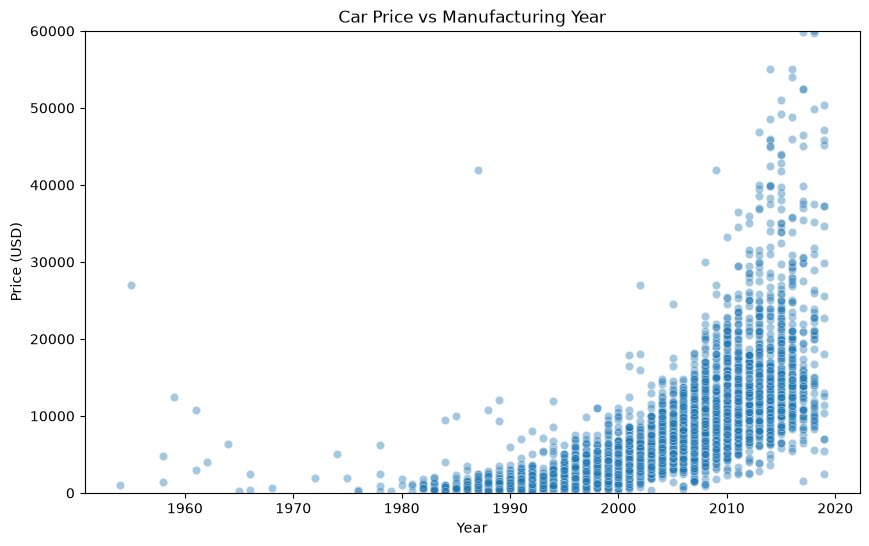

In [6]:
plt.figure(figsize=(10, 6))

sample_df = model_df.sample(
    min(5000, len(model_df)),
    random_state=42
)

sns.scatterplot(
    data=sample_df,
    x="year",
    y="priceUSD",
    alpha=0.4
)

plt.title("Car Price vs Manufacturing Year")
plt.xlabel("Year")
plt.ylabel("Price (USD)")
plt.ylim(0, 60000)

plt.show()

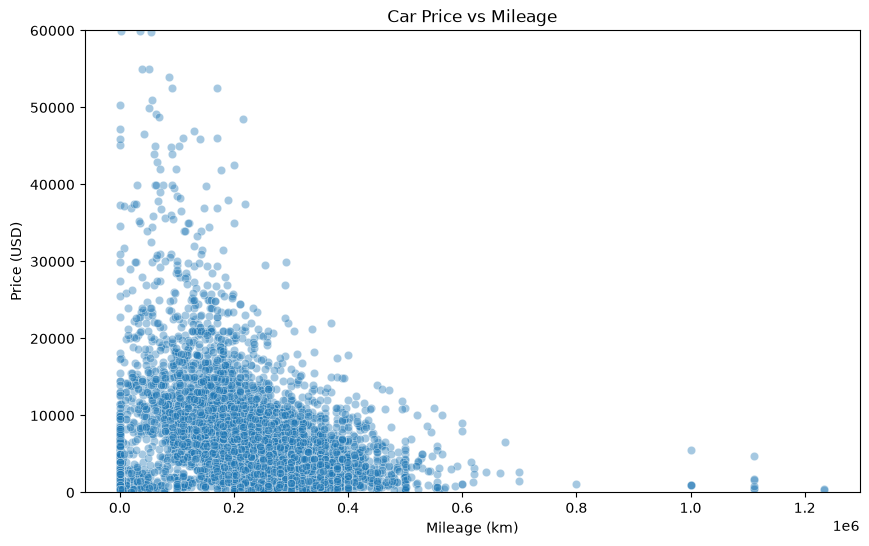

In [7]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample_df,
    x="mileage_km",
    y="priceUSD",
    alpha=0.4
)

plt.title("Car Price vs Mileage")
plt.xlabel("Mileage (km)")
plt.ylabel("Price (USD)")
plt.ylim(0, 60000)

plt.show()

Newer vehicles generally have higher prices, while higher mileage tends to be associated with lower market value.

These relationships are not perfectly linear because price also depends on brand, model, engine, condition and other characteristics.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor

from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [9]:
X = model_df[FEATURES]
y = model_df["priceUSD"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training cars:", len(X_train))
print("Testing cars:", len(X_test))

Training cars: 44711
Testing cars: 11178


## 3. Model Training and Comparison

Three regression algorithms are evaluated:

- Ridge Regression
- Decision Tree Regressor
- Random Forest Regressor

All models use the same preprocessing pipeline and the same training and testing datasets.

Because the car price distribution is strongly skewed, the target price is transformed using a logarithmic transformation during training.

In [10]:
models = {
    "Ridge Regression": Ridge(
        alpha=10.0
    ),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=25,
        min_samples_leaf=2,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=60,
        max_depth=24,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, regressor in models.items():

    pipeline = Pipeline([
        (
            "preprocessor",
            build_preprocessor()
        ),
        (
            "regressor",
            regressor
        )
    ])

    model = TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log1p,
        inverse_func=np.expm1
    )

    print(f"Training {name}...")

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_test
    )

    predictions = np.maximum(
        predictions,
        0
    )

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    mse = mean_squared_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test,
        predictions
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models[name] = model

    print(f"MAE:  ${mae:,.2f}")
    print(f"RMSE: ${rmse:,.2f}")
    print(f"R2:    {r2:.4f}")
    print()

Training Ridge Regression...
MAE:  $1,254.90
RMSE: $3,110.51
R2:    0.8588

Training Decision Tree...
MAE:  $1,360.39
RMSE: $3,329.84
R2:    0.8382

Training Random Forest...
MAE:  $1,098.16
RMSE: $2,734.31
R2:    0.8909



In [11]:
results_df = pd.DataFrame(
    results
)

results_df = results_df.sort_values(
    by="MAE"
).reset_index(drop=True)

results_df.round(3)

,Model,MAE,MSE,RMSE,R2
0,Random Forest,1098.164,7.476451e+06,2734.310,0.891
1,Ridge Regression,1254.901,9.675254e+06,3110.507,0.859
2,Decision Tree,1360.392,1.108783e+07,3329.839,0.838


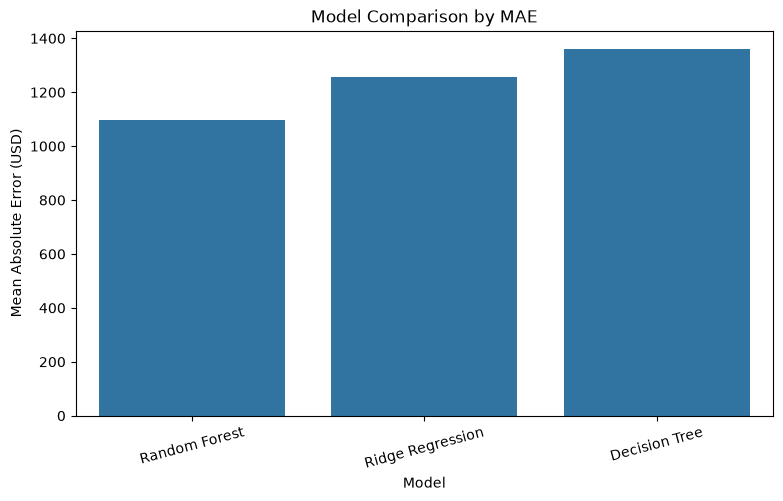

In [12]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE"
)

plt.title("Model Comparison by MAE")
plt.ylabel("Mean Absolute Error (USD)")
plt.xlabel("Model")
plt.xticks(rotation=15)

plt.show()

Random Forest achieved the lowest MAE and RMSE and the highest R² score.

An MAE of approximately $1,100 means that the model's predicted price differs from the real price by about $1,100 on average.

Based on all evaluation metrics, Random Forest was selected as the final model.

In [13]:
best_model = trained_models[
    "Random Forest"
]

best_predictions = best_model.predict(
    X_test
)

best_predictions = np.maximum(
    best_predictions,
    0
)

mae = mean_absolute_error(
    y_test,
    best_predictions
)

mse = mean_squared_error(
    y_test,
    best_predictions
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test,
    best_predictions
)

print("FINAL MODEL EVALUATION")
print("=" * 60)

print(f"MAE:  ${mae:,.2f}")
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R2:    {r2:.4f}")

FINAL MODEL EVALUATION
MAE:  $1,098.16
MSE:  7,476,450.80
RMSE: $2,734.31
R2:    0.8909


In [14]:
comparison = pd.DataFrame({
    "Actual Price":
        y_test.iloc[:10].values,

    "Predicted Price":
        best_predictions[:10]
})

comparison["Absolute Error"] = (
    comparison["Actual Price"]
    -
    comparison["Predicted Price"]
).abs()

comparison.round(2)

,Actual Price,Predicted Price,Absolute Error
0,13800,15450.20,1650.20
1,16500,14100.27,2399.73
2,8000,8079.05,79.05
3,17000,13919.51,3080.49
4,14500,14579.40,79.40
5,1000,860.13,139.87
6,2282,2772.20,490.20
7,10850,11527.68,677.68
8,9100,7398.82,1701.18
9,3200,3314.13,114.13


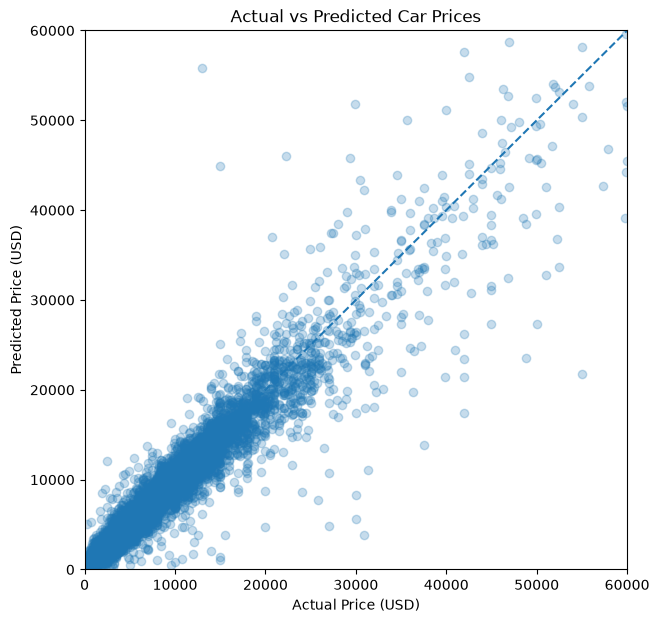

In [15]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.25
)

maximum = min(
    60000,
    max(
        y_test.max(),
        best_predictions.max()
    )
)

plt.plot(
    [0, maximum],
    [0, maximum],
    linestyle="--"
)

plt.xlim(0, maximum)
plt.ylim(0, maximum)

plt.xlabel("Actual Price (USD)")
plt.ylabel("Predicted Price (USD)")
plt.title("Actual vs Predicted Car Prices")

plt.show()

## 4. Conclusion

The goal of this project was to develop a regression model for estimating the market price of used cars.

The original dataset contained 56,244 vehicles. After removing only clearly unrealistic extreme values, 55,889 records remained for model development.

Missing numerical and categorical values were handled through preprocessing pipelines rather than deleting large numbers of useful observations.

Several additional features were created, including vehicle age, average mileage per year, engine volume in liters, indicators for newer and high-mileage vehicles and a combined brand-model feature.

Three regression algorithms were evaluated using the same training and test split:

- Ridge Regression
- Decision Tree Regressor
- Random Forest Regressor

Random Forest achieved the best overall results, with an MAE of approximately $1,100, RMSE of approximately $2,700 and an R² score of approximately 0.89.

The MAE means that, on average, the predicted price differs from the actual listed price by roughly $1,100.

The model is not expected to predict every vehicle price perfectly because real market prices also depend on factors that may not be available in the dataset. However, the results show that the available vehicle characteristics contain enough information to provide a useful automatic price estimate.

Random Forest was therefore selected as the final model.